# Deep Learning Assignment 3 – CO3

This notebook provides implementations and experiments for Q1–Q7.


## 0. Setup and configuration

In [ ]:
import os, time, math, random, warnings, itertools
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score,
                             precision_recall_curve, mean_absolute_error,
                             mean_squared_error, classification_report,
                             confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)

set_seed()
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


# Q1 – Unfolding the Recurrence and Sharing Parameters

Given: h(t) = tanh(w*x(t) + u*h(t-1) + b), y_hat(t) = v*h(t)  
w=0.5, u=0.8, b=0, v=2, h0=0, x=(1,2,-1).

This section calculates each time step, tests changed recurrent weights, draws the unfolded graph, and compares a one-unit RNN with a one-hidden-unit feedforward model.

,t,x_t,h_(t-1),z_t,h_t,y_hat_t
0,1,1.0,0.000000,0.500000,0.462117,0.924234
1,2,2.0,0.462117,1.369694,0.878622,1.757245
2,3,-1.0,0.878622,0.202898,0.200159,0.400317


Final prediction y_hat_3 = 0.4003174532298192
Approximate sensitivity dy3/dx1 = 0.11017180482353338


,u,h3,y_hat3
0,0.2,-0.327877,-0.655754
1,0.8,0.200159,0.400317
2,1.5,0.717186,1.434371


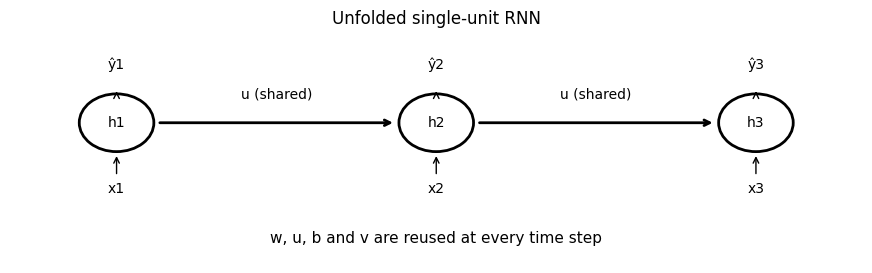

,window_length,RNN_parameters,feedforward_parameters
0,3,5,6
1,24,5,27
2,168,5,171


,model,window,parameters,training_seconds,test_MSE
0,RNN,3,5,9.495171,336.348999
1,Feedforward,3,6,5.798801,332.441406
2,RNN,24,5,9.435663,315.587799
3,Feedforward,24,27,5.540882,335.201019
4,RNN,168,5,15.305774,380.275391
5,Feedforward,168,171,1.774488,418.041260


In [ ]:
# Q1A: Hand-computation values and forward-pass verification
w, u, b, v, h = 0.5, 0.8, 0.0, 2.0, 0.0
x_seq = [1.0, 2.0, -1.0]
rows = []
for t, x in enumerate(x_seq, start=1):
    previous_h = h
    z = w*x + u*previous_h + b
    h = np.tanh(z)
    y = v*h
    rows.append({"t":t, "x_t":x, "h_(t-1)":previous_h, "z_t":z, "h_t":h, "y_hat_t":y})
q1_forward = pd.DataFrame(rows)
display(q1_forward)
print("Final prediction y_hat_3 =", q1_forward.iloc[-1]["y_hat_t"])

# Influence of x1 on y3: finite-difference sensitivity
def final_output(x_values, recurrent_weight=0.8):
    ht = 0.0
    for xt in x_values:
        ht = np.tanh(0.5*xt + recurrent_weight*ht)
    return 2.0*ht
eps = 1e-5
x_plus = [1+eps, 2, -1]
x_minus = [1-eps, 2, -1]
print("Approximate sensitivity dy3/dx1 =", (final_output(x_plus)-final_output(x_minus))/(2*eps))

# Change u to 0.2 and 1.5
change_rows = []
for uu in [0.2, 0.8, 1.5]:
    hh = 0.0
    for xx in x_seq:
        hh = np.tanh(0.5*xx + uu*hh)
    change_rows.append({"u":uu, "h3":hh, "y_hat3":2*hh})
display(pd.DataFrame(change_rows))

# Draw unfolded RNN computational graph
fig, ax = plt.subplots(figsize=(11,3))
for i, xpos in enumerate([1,4,7]):
    ax.add_patch(plt.Circle((xpos,1.5),0.35,fill=False,lw=2))
    ax.text(xpos,1.5,f"h{i+1}",ha="center",va="center")
    ax.text(xpos,0.65,f"x{i+1}",ha="center")
    ax.annotate("",xy=(xpos,1.13),xytext=(xpos,0.85),arrowprops=dict(arrowstyle="->"))
    ax.text(xpos,2.15,"ŷ"+str(i+1),ha="center")
    ax.annotate("",xy=(xpos,1.88),xytext=(xpos,1.85),arrowprops=dict(arrowstyle="->"))
for a,bx in [(1,4),(4,7)]:
    ax.annotate("",xy=(bx-0.38,1.5),xytext=(a+0.38,1.5),arrowprops=dict(arrowstyle="->",lw=2))
    ax.text((a+bx)/2,1.8,"u (shared)",ha="center")
ax.text(4,0.05,"w, u, b and v are reused at every time step",ha="center",fontsize=11)
ax.set_xlim(0,8); ax.set_ylim(-0.2,2.6); ax.axis("off"); plt.title("Unfolded single-unit RNN"); plt.show()

# Q1B: Parameter counts
# Simple RNN one hidden unit: input weight + recurrent weight + bias + output weight + output bias = 5.
# Flat feedforward model with window length L and one hidden unit: L input weights + hidden bias + output weight + output bias = L+3.
counts=[]
for L in [3,24,168]:
    counts.append({"window_length":L,"RNN_parameters":5,"feedforward_parameters":L+3})
q1_counts = pd.DataFrame(counts)
display(q1_counts)

# Synthetic seasonal hourly series for a fair illustrative comparison
def make_hourly_series(n=2400, seed=11):
    rng=np.random.default_rng(seed)
    t=np.arange(n)
    return (20 + 5*np.sin(2*np.pi*t/24) + 2*np.sin(2*np.pi*t/(24*7))
            + 0.8*np.sin(2*np.pi*t/168) + rng.normal(0,0.6,n)).astype("float32")
series=make_hourly_series()
def windows(arr, L):
    X=np.array([arr[i:i+L] for i in range(len(arr)-L)],dtype="float32")
    y=np.array([arr[i+L] for i in range(len(arr)-L)],dtype="float32")
    return X,y

def train_q1_models(L, epochs=8):
    X,y=windows(series,L)
    split=int(len(X)*0.8)
    Xtr,Xte,ytr,yte=X[:split],X[split:],y[:split],y[split:]
    # RNN: sequence input, one recurrent unit, one output
    rnn=keras.Sequential([layers.Input((L,1)),layers.SimpleRNN(1),layers.Dense(1)])
    # Feedforward: same window flattened, one hidden unit
    ff=keras.Sequential([layers.Input((L,)),layers.Dense(1,activation="tanh"),layers.Dense(1)])
    results=[]
    for name,model,xxtr,xxte in [
        ("RNN",rnn,Xtr[...,None],Xte[...,None]),("Feedforward",ff,Xtr,Xte)]:
        model.compile(optimizer="adam",loss="mse")
        start=time.time()
        model.fit(xxtr,ytr,epochs=epochs,batch_size=32,verbose=0)
        elapsed=time.time()-start
        pred=model.predict(xxte,verbose=0).ravel()
        results.append({"model":name,"window":L,"parameters":model.count_params(),
                        "training_seconds":elapsed,"test_MSE":mean_squared_error(yte,pred)})
    return results

q1_exp=[]
for L in [3,24,168]:
    q1_exp += train_q1_models(L)
q1_experiment=pd.DataFrame(q1_exp)
display(q1_experiment)

# Q2 – Why Do Gradients Vanish or Explode? (7 marks)

A 32-unit vanilla RNN is tested at sequence lengths 10, 25, 50 and 100. The recurrent matrix is initialized with largest singular values 0.5, 1.0 and 1.5. We measure the gradient norm reaching the first time step, then apply global-norm clipping.

,spectral_norm,sequence_length,gradient_norm_before_clipping,gradient_norm_after_clipping
0,0.5,10,3.070834e-05,3.070834e-05
1,0.5,25,8.299390e-10,8.299390e-10
2,0.5,50,1.968627e-17,1.968627e-17
3,0.5,100,0.000000e+00,0.000000e+00
4,1.0,10,3.968119e-02,3.968119e-02
5,1.0,25,2.586191e-02,2.586191e-02
6,1.0,50,1.735552e-02,1.735552e-02
7,1.0,100,6.299507e-03,6.299507e-03
8,1.5,10,1.288720e+00,1.000000e+00
9,1.5,25,1.251253e+00,9.999999e-01


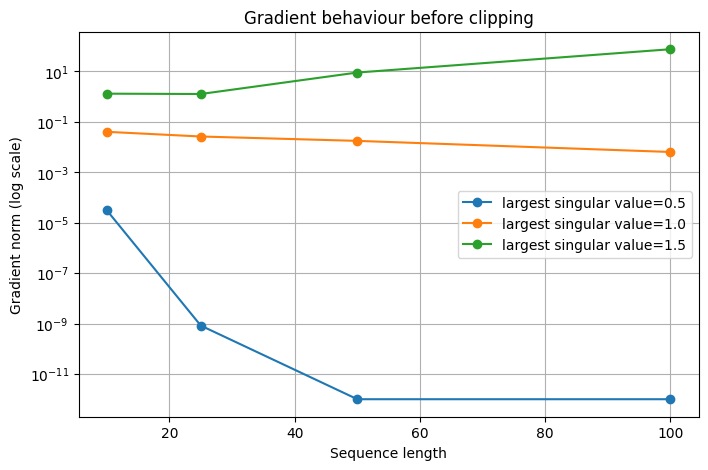

Single-unit recurrence: dh_t/dh_(t-1) = u * (1 - h_t^2)
Across T steps: dh_T/dh_1 is the product of these local derivatives.
Vector RNN: Jacobian product contains diag(1-h_t^2) @ U at each step.


In [ ]:
# Q2: RNN gradient experiment using TensorFlow GradientTape
HIDDEN=32
def orthogonal_with_spectral_norm(size, target_norm, seed):
    rng=np.random.default_rng(seed)
    a=rng.normal(size=(size,size))
    q,_=np.linalg.qr(a)
    return (q*target_norm).astype("float32")

def measure_rnn_gradient(seq_len, spectral_norm, clip_norm=None, seed=1):
    set_seed(seed)
    U=orthogonal_with_spectral_norm(HIDDEN,spectral_norm,seed)
    W=tf.Variable(tf.random.normal((1,HIDDEN),stddev=0.1,seed=seed))
    Uvar=tf.Variable(U)
    b=tf.Variable(tf.zeros((HIDDEN,)))
    x=tf.ones((1,seq_len,1))
    with tf.GradientTape() as tape:
        h=tf.zeros((1,HIDDEN))
        states=[]
        for t in range(seq_len):
            h=tf.tanh(tf.matmul(x[:,t,:],W)+tf.matmul(h,Uvar)+b)
            states.append(h)
        loss=tf.reduce_mean(tf.square(states[-1]))
    grads=tape.gradient(loss,[W,Uvar,b])
    # Gradient reaching the first time step is approximated by differentiating
    # final loss with respect to the first hidden state in a second explicit unroll.
    with tf.GradientTape() as tape2:
        h0=tf.Variable(tf.zeros((1,HIDDEN)))
        tape2.watch(h0)
        h=h0
        for t in range(seq_len):
            h=tf.tanh(tf.matmul(x[:,t,:],W)+tf.matmul(h,Uvar)+b)
        loss2=tf.reduce_mean(tf.square(h))
    g0=tape2.gradient(loss2,h0)
    raw=float(tf.linalg.global_norm([g0]).numpy())
    if clip_norm is not None:
        clipped,_=tf.clip_by_global_norm([g0],clip_norm)
        measured=float(tf.linalg.global_norm(clipped).numpy())
    else:
        measured=raw
    return raw,measured

q2_rows=[]
for sn in [0.5,1.0,1.5]:
    for L in [10,25,50,100]:
        raw,clipped=measure_rnn_gradient(L,sn,clip_norm=1.0)
        q2_rows.append({"spectral_norm":sn,"sequence_length":L,
                        "gradient_norm_before_clipping":raw,
                        "gradient_norm_after_clipping":clipped})
q2_df=pd.DataFrame(q2_rows)
display(q2_df)
plt.figure(figsize=(8,5))
for sn,grp in q2_df.groupby("spectral_norm"):
    plt.plot(grp.sequence_length,np.maximum(grp.gradient_norm_before_clipping,1e-12),
             marker="o",label=f"largest singular value={sn}")
plt.yscale("log"); plt.xlabel("Sequence length"); plt.ylabel("Gradient norm (log scale)")
plt.title("Gradient behaviour before clipping"); plt.legend(); plt.grid(True); plt.show()

# Single-unit derivative and vector-RNN Jacobian discussion values
print("Single-unit recurrence: dh_t/dh_(t-1) = u * (1 - h_t^2)")
print("Across T steps: dh_T/dh_1 is the product of these local derivatives.")
print("Vector RNN: Jacobian product contains diag(1-h_t^2) @ U at each step.")

# Q3 – Engineering Long-Range Memory: RNN vs LSTM vs GRU

Synthetic trigger-memory task: a binary pulse is placed L steps before the end; the label indicates whether the pulse was present. All models use the same hidden size, optimiser, learning rate and epoch budget.

,lag,model,test_accuracy,epochs_to_90pct_val_accuracy,training_seconds,parameters
0,5,Vanilla RNN,1.000000,1,4.225986,1121
1,5,LSTM,1.000000,3,3.913374,4385
2,5,GRU,1.000000,3,4.156645,3393
3,20,Vanilla RNN,1.000000,1,4.660537,1121
4,20,LSTM,1.000000,2,4.637326,4385
5,20,GRU,1.000000,6,6.992949,3393
6,50,Vanilla RNN,0.970000,1,4.185524,1121
7,50,LSTM,1.000000,6,9.593488,4385
8,50,GRU,0.488333,not reached,8.606776,3393
9,100,Vanilla RNN,1.000000,2,5.908190,1121


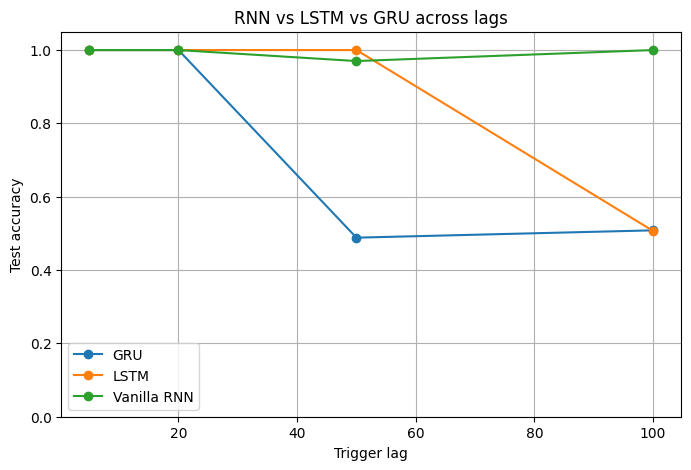

In [ ]:
# Q3: Generate balanced synthetic sequences for a specified lag
def make_trigger_data(lag, n=2400, seed=123):
    rng=np.random.default_rng(seed)
    X=rng.normal(0,0.15,size=(n,lag+1,1)).astype("float32")
    y=rng.integers(0,2,size=n).astype("float32")
    X[:,0,0] += y*2.0  # decisive pulse is exactly lag steps before the final step
    return X,y

def build_sequence_model(kind, timesteps, hidden=32):
    inp=keras.Input(shape=(timesteps,1))
    if kind=="Vanilla RNN":
        x=layers.SimpleRNN(hidden)(inp)
    elif kind=="LSTM":
        x=layers.LSTM(hidden)(inp)
    else:
        x=layers.GRU(hidden)(inp)
    out=layers.Dense(1,activation="sigmoid")(x)
    return keras.Model(inp,out)

q3_rows=[]
for lag in [5,20,50,100]:
    X,y=make_trigger_data(lag)
    Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.25,random_state=SEED,stratify=y)
    for kind in ["Vanilla RNN","LSTM","GRU"]:
        set_seed(SEED)
        model=build_sequence_model(kind,lag+1,hidden=32)
        model.compile(optimizer=keras.optimizers.Adam(0.001),
                      loss="binary_crossentropy",metrics=["accuracy"])
        start=time.time()
        hist=model.fit(Xtr,ytr,validation_split=0.2,epochs=8,batch_size=64,verbose=0)
        elapsed=time.time()-start
        prob=model.predict(Xte,verbose=0).ravel()
        pred=(prob>=0.5).astype(int)
        reached=next((i+1 for i,a in enumerate(hist.history["val_accuracy"]) if a>=0.90),None)
        q3_rows.append({"lag":lag,"model":kind,"test_accuracy":accuracy_score(yte,pred),
                        "epochs_to_90pct_val_accuracy":reached if reached else "not reached",
                        "training_seconds":elapsed,"parameters":model.count_params()})
q3_df=pd.DataFrame(q3_rows)
display(q3_df)
plt.figure(figsize=(8,5))
for kind,grp in q3_df.groupby("model"):
    plt.plot(grp.lag,grp.test_accuracy,marker="o",label=kind)
plt.xlabel("Trigger lag"); plt.ylabel("Test accuracy"); plt.ylim(0,1.05)
plt.title("RNN vs LSTM vs GRU across lags"); plt.legend(); plt.grid(True); plt.show()

# Q4 – Depth and Direction in Recurrent Networks

Uses the public IMDB movie-review sentiment dataset available through Keras. The three configurations are single-layer LSTM, two-layer stacked LSTM and bidirectional LSTM. To keep Colab runtime manageable, the default uses a subset of the dataset and two epochs. Increase the settings below for a more extensive experiment. The three-seed loop is included.

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (6000, 200) Test: (2000, 200)


,seed,configuration,accuracy,F1,parameters,training_seconds,inference_ms_per_review
0,7,Single-layer LSTM,0.7720,0.749726,673089,29.153189,0.798337
1,7,Stacked 2-layer LSTM,0.7730,0.727491,706113,56.206050,1.551697
2,7,Bidirectional LSTM,0.8075,0.787645,706177,85.813108,1.340160
3,21,Single-layer LSTM,0.7905,0.789553,673089,29.566880,1.242437
4,21,Stacked 2-layer LSTM,0.7830,0.793726,706113,54.756539,1.904640
5,21,Bidirectional LSTM,0.7985,0.802934,706177,78.169386,2.259305
6,42,Single-layer LSTM,0.7325,0.757149,673089,30.359851,0.816711
7,42,Stacked 2-layer LSTM,0.7195,0.613902,706113,85.063186,3.171609
8,42,Bidirectional LSTM,0.8060,0.782998,706177,52.786497,1.677112


seed           accuracy                  F1  \
                           mean       std     mean       std      mean   
configuration                                                            
Bidirectional LSTM    23.333333  17.61628   0.8040  0.004822  0.791192   
Single-layer LSTM     23.333333  17.61628   0.7650  0.029627  0.765476   
Stacked 2-layer LSTM  23.333333  17.61628   0.7585  0.034143  0.711707   

                               parameters      training_seconds             \
                           std       mean  std             mean        std   
configuration                                                                
Bidirectional LSTM    0.010431   706177.0  0.0        72.256330  17.289084   
Single-layer LSTM     0.021179   673089.0  0.0        29.693306   0.613185   
Stacked 2-layer LSTM  0.090945   706113.0  0.0        65.341925  17.094484   

                     inference_ms_per_review            
                                        mean       std  
configuration                                           
Bidirectional LSTM                  1.758859  0.464994  
Single-layer LSTM                   0.952495  0.251265  
Stacked 2-layer LSTM                2.209316  0.851850

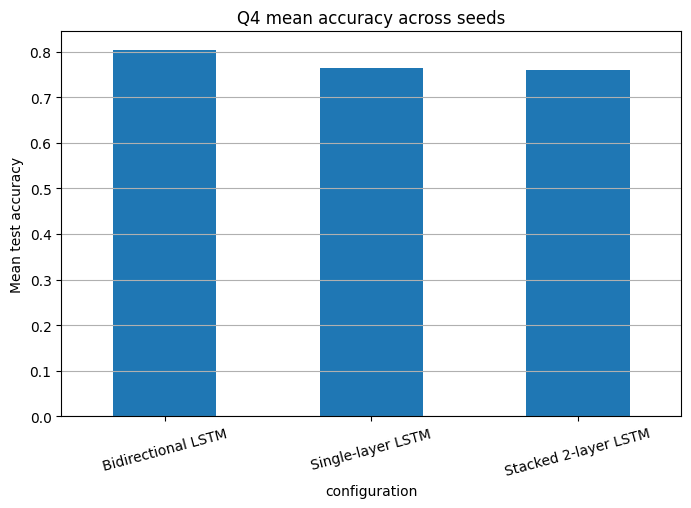

Note: Bidirectional LSTM uses both earlier and later tokens in a completed review.
It is not valid for causal live forecasting when future inputs are not yet available.


In [ ]:
# Q4: Configurable IMDB experiment
VOCAB_SIZE=10000
MAX_LEN=200
TRAIN_LIMIT=6000       # set to 20000 or None for a larger experiment
TEST_LIMIT=2000        # set to None for full test set
Q4_EPOCHS=2            # increase to 5+ for stronger training
Q4_SEEDS=[7,21,42]     # assignment asks for at least three seeds

(x_train,y_train),(x_test,y_test)=keras.datasets.imdb.load_data(num_words=VOCAB_SIZE)
x_train=keras.preprocessing.sequence.pad_sequences(x_train,maxlen=MAX_LEN)
x_test=keras.preprocessing.sequence.pad_sequences(x_test,maxlen=MAX_LEN)
if TRAIN_LIMIT: x_train,y_train=x_train[:TRAIN_LIMIT],y_train[:TRAIN_LIMIT]
if TEST_LIMIT: x_test,y_test=x_test[:TEST_LIMIT],y_test[:TEST_LIMIT]
print("Train:",x_train.shape,"Test:",x_test.shape)

def build_q4_model(config):
    inp=keras.Input(shape=(MAX_LEN,))
    x=layers.Embedding(VOCAB_SIZE,64)(inp)
    if config=="Single-layer LSTM":
        x=layers.LSTM(64)(x)
    elif config=="Stacked 2-layer LSTM":
        x=layers.LSTM(64,return_sequences=True)(x)
        x=layers.LSTM(64)(x)
    else:
        x=layers.Bidirectional(layers.LSTM(64))(x)
    out=layers.Dense(1,activation="sigmoid")(x)
    return keras.Model(inp,out)

q4_rows=[]
for seed in Q4_SEEDS:
    for config in ["Single-layer LSTM","Stacked 2-layer LSTM","Bidirectional LSTM"]:
        set_seed(seed)
        model=build_q4_model(config)
        model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
        start=time.time()
        model.fit(x_train,y_train,validation_split=0.2,epochs=Q4_EPOCHS,batch_size=128,verbose=0)
        train_seconds=time.time()-start
        start=time.time()
        probs=model.predict(x_test,batch_size=256,verbose=0).ravel()
        inference_seconds=time.time()-start
        preds=(probs>=0.5).astype(int)
        q4_rows.append({"seed":seed,"configuration":config,
                        "accuracy":accuracy_score(y_test,preds),
                        "F1":f1_score(y_test,preds),
                        "parameters":model.count_params(),
                        "training_seconds":train_seconds,
                        "inference_ms_per_review":1000*inference_seconds/len(x_test)})
q4_df=pd.DataFrame(q4_rows)
display(q4_df)
display(q4_df.groupby("configuration").agg(["mean","std"],numeric_only=True))
plt.figure(figsize=(8,5))
q4_df.groupby("configuration").accuracy.mean().plot(kind="bar")
plt.ylabel("Mean test accuracy"); plt.title("Q4 mean accuracy across seeds")
plt.xticks(rotation=15); plt.grid(axis="y"); plt.show()
print("Note: Bidirectional LSTM uses both earlier and later tokens in a completed review.")
print("It is not valid for causal live forecasting when future inputs are not yet available.")

# Q5 – Upgrading the Chain to a Tree: Recursive Neural Networks

The phrase is “the battery drains very quickly”. This section creates 2-D word vectors, performs recursive composition using p=tanh(W[c1;c2]+b), prints each internal node, and compares chain/tree path lengths and gradient flow.

(the battery) = [0.30951 0.17808]
(very quickly) = [0.21652 0.14399]
(drains (very quickly)) = [-0.02064  0.2787 ]
ROOT phrase vector = [0.11526 0.00526]
Final phrase representation: [0.11526 0.00526]


,words,chain_compositions,balanced_tree_compositions_on_longest_path
0,8,7,3
1,64,63,6
2,512,511,9


,words,chain_first_word_gradient_norm,balanced_tree_first_word_gradient_norm
0,8,4.965434e-08,1.602697e-04
1,64,0.000000e+00,1.619053e-08
2,512,0.000000e+00,1.278480e-15


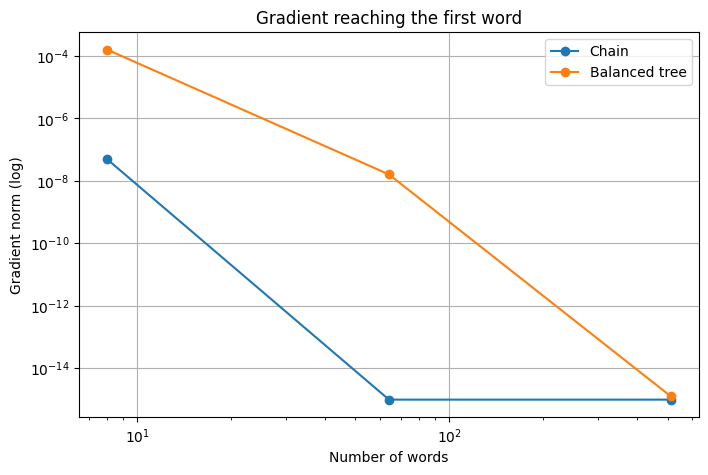

In [ ]:
# Q5A: Explicit example parse tree:
#                 ROOT
#                /    \
#          "the battery" "drains very quickly"
# Word vectors are illustrative 2-D embeddings chosen for transparent calculation.
word_vec={
    "the":np.array([0.1,0.2]), "battery":np.array([0.8,0.3]),
    "drains":np.array([-0.4,0.7]), "very":np.array([0.2,0.6]),
    "quickly":np.array([0.7,-0.2])
}
W=np.array([[0.2,-0.1,0.3,0.1],[-0.2,0.25,0.15,0.2]],dtype=float)
bias=np.array([0.05,-0.03])
def compose(left,right,label):
    z=W@np.concatenate([left,right])+bias
    p=np.tanh(z)
    print(label, "=", np.round(p,5))
    return p

the_battery=compose(word_vec["the"],word_vec["battery"],"(the battery)")
very_quickly=compose(word_vec["very"],word_vec["quickly"],"(very quickly)")
drains_vq=compose(word_vec["drains"],very_quickly,"(drains (very quickly))")
root=compose(the_battery,drains_vq,"ROOT phrase vector")
print("Final phrase representation:",np.round(root,5))

# Q5B: Longest path length for a left-associated chain vs balanced binary tree
def balanced_depth(n):
    return int(math.ceil(math.log2(n)))
path_rows=[]
for n in [8,64,512]:
    path_rows.append({"words":n,"chain_compositions":n-1,
                      "balanced_tree_compositions_on_longest_path":balanced_depth(n)})
q5_paths=pd.DataFrame(path_rows)
display(q5_paths)

# Gradient norm reaching first word for chain and balanced tree.
# A shared composition function is used in both structures.
def compose_torchless(a,b,Wm,bm):
    return np.tanh(Wm@np.concatenate([a,b])+bm)
def chain_root(vecs,Wm,bm):
    h=vecs[0]
    for vec in vecs[1:]:
        h=compose_torchless(h,vec,Wm,bm)
    return h
def balanced_root(vecs,Wm,bm):
    nodes=list(vecs)
    while len(nodes)>1:
        nxt=[]
        for i in range(0,len(nodes),2):
            if i+1<len(nodes): nxt.append(compose_torchless(nodes[i],nodes[i+1],Wm,bm))
            else: nxt.append(nodes[i])
        nodes=nxt
    return nodes[0]
def finite_grad_first(builder,vecs,Wm,bm,eps=1e-5):
    base=[v.copy() for v in vecs]
    grad=np.zeros_like(base[0])
    for j in range(len(grad)):
        plus=[v.copy() for v in base]; minus=[v.copy() for v in base]
        plus[0][j]+=eps; minus[0][j]-=eps
        fp=np.sum(builder(plus,Wm,bm)**2); fm=np.sum(builder(minus,Wm,bm)**2)
        grad[j]=(fp-fm)/(2*eps)
    return np.linalg.norm(grad)
rng=np.random.default_rng(9)
q5_grad=[]
for n in [8,64,512]:
    vecs=[rng.normal(0,0.2,2) for _ in range(n)]
    Wm=rng.normal(0,0.2,(2,4)); bm=np.zeros(2)
    q5_grad.append({"words":n,
                    "chain_first_word_gradient_norm":finite_grad_first(chain_root,vecs,Wm,bm),
                    "balanced_tree_first_word_gradient_norm":finite_grad_first(balanced_root,vecs,Wm,bm)})
q5_grad_df=pd.DataFrame(q5_grad)
display(q5_grad_df)
plt.figure(figsize=(8,5))
plt.plot(q5_grad_df.words,np.maximum(q5_grad_df.chain_first_word_gradient_norm,1e-15),marker="o",label="Chain")
plt.plot(q5_grad_df.words,np.maximum(q5_grad_df.balanced_tree_first_word_gradient_norm,1e-15),marker="o",label="Balanced tree")
plt.yscale("log"); plt.xscale("log"); plt.xlabel("Number of words"); plt.ylabel("Gradient norm (log)")
plt.title("Gradient reaching the first word"); plt.legend(); plt.grid(True); plt.show()

# Q6 – Practical Methodology Mini-Investigations

Part A creates an imbalanced fraud sequence dataset with 2% positive examples, demonstrates why accuracy is misleading, calculates precision/recall/F1/PR-AUC and selects a threshold that limits alerts to 50 per day. It also demonstrates a training instability. Part B compares grid search and random search with 20 trials each.

Majority baseline accuracy: 0.98
Majority baseline recall: 0.0
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      2450
           1       1.00      0.66      0.80        50

    accuracy                           0.99      2500
   macro avg       1.00      0.83      0.90      2500
weighted avg       0.99      0.99      0.99      2500

PR-AUC: 0.918411157421577


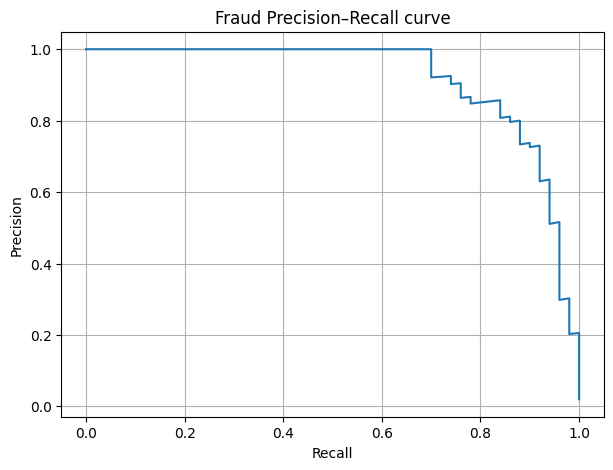

Selected threshold (top-50 alert capacity): 0.25301873683929443
Alerts selected: 50
Precision at capacity: 0.84
Recall at capacity: 0.84
High-learning-rate loss history: [0.06992869079113007, 0.02018660493195057, 0.019218193367123604]
If loss becomes NaN/unstable: inspect learning rate and gradient norms; reduce LR, clip gradients, and normalize inputs.


In [ ]:
# Q6A: Synthetic imbalanced transaction sequences
def make_fraud_data(n=10000, timesteps=12, seed=55):
    rng=np.random.default_rng(seed)
    y=np.zeros(n,dtype=int)
    positive=rng.choice(n,size=max(1,int(0.02*n)),replace=False)
    y[positive]=1
    X=rng.normal(0,1,(n,timesteps,4)).astype("float32")
    # Fraud signal is stronger in a few features/time positions.
    X[y==1,-3:,0]+=2.2
    X[y==1,-3:,1]-=1.5
    return X,y
Xfraud,yfraud=make_fraud_data()
Xtr,Xte,ytr,yte=train_test_split(Xfraud,yfraud,test_size=0.25,random_state=SEED,stratify=yfraud)
# Majority-class baseline: high accuracy but zero fraud detection
majority_pred=np.zeros_like(yte)
print("Majority baseline accuracy:",accuracy_score(yte,majority_pred))
print("Majority baseline recall:",recall_score(yte,majority_pred,zero_division=0))

fraud_model=keras.Sequential([
    layers.Input((12,4)), layers.GRU(16), layers.Dense(1,activation="sigmoid")
])
fraud_model.compile(optimizer="adam",loss="binary_crossentropy")
fraud_model.fit(Xtr,ytr,epochs=5,batch_size=128,verbose=0)
fraud_prob=fraud_model.predict(Xte,verbose=0).ravel()
fraud_pred=(fraud_prob>=0.5).astype(int)
print(classification_report(yte,fraud_pred,zero_division=0))
print("PR-AUC:",average_precision_score(yte,fraud_prob))
p,r,th=precision_recall_curve(yte,fraud_prob)
plt.figure(figsize=(7,5)); plt.plot(r,p); plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Fraud Precision–Recall curve"); plt.grid(True); plt.show()

# Threshold constrained by alert review capacity: 50 alerts/day.
# Synthetic test data is treated as one evaluation day for this demonstration.
capacity=min(50,len(fraud_prob))
order=np.argsort(fraud_prob)[::-1]
threshold=float(fraud_prob[order[capacity-1]]) if capacity>0 else 1.0
capacity_pred=(fraud_prob>=threshold).astype(int)
# Resolve ties to ensure no more than capacity alerts.
if capacity_pred.sum()>capacity:
    capacity_pred[:]=0
    capacity_pred[order[:capacity]]=1
print("Selected threshold (top-50 alert capacity):",threshold)
print("Alerts selected:",int(capacity_pred.sum()))
print("Precision at capacity:",precision_score(yte,capacity_pred,zero_division=0))
print("Recall at capacity:",recall_score(yte,capacity_pred,zero_division=0))

# Demonstration of a training failure: deliberately excessive learning rate.
bad_model=keras.Sequential([layers.Input((12,4)),layers.GRU(8),layers.Dense(1,activation="sigmoid")])
bad_model.compile(optimizer=keras.optimizers.SGD(learning_rate=5.0),
                  loss="binary_crossentropy")
bad_history=bad_model.fit(Xtr[:1024],ytr[:1024],epochs=3,batch_size=32,verbose=0)
print("High-learning-rate loss history:",bad_history.history["loss"])
print("If loss becomes NaN/unstable: inspect learning rate and gradient norms; reduce LR, clip gradients, and normalize inputs.")

,method,trial,learning_rate,hidden_size,dropout,validation_PR_AUC,parameters
26,Random Search,7,0.0050,32,0.4,0.782208,3681
38,Random Search,19,0.0050,32,0.2,0.771248,3681
21,Random Search,2,0.0050,32,0.0,0.692135,3681
18,Grid Search,19,0.0010,8,0.0,0.620062,345
5,Grid Search,6,0.0001,16,0.4,0.493702,1073
23,Random Search,4,0.0005,16,0.4,0.420367,1073
3,Grid Search,4,0.0001,16,0.0,0.399396,1073
14,Grid Search,15,0.0005,16,0.4,0.344314,1073
32,Random Search,13,0.0050,16,0.0,0.281980,1073
6,Grid Search,7,0.0001,32,0.0,0.232600,3681


,method,trial,learning_rate,hidden_size,dropout,validation_PR_AUC,parameters
18,Grid Search,19,0.001,8,0.0,0.620062,345
26,Random Search,7,0.005,32,0.4,0.782208,3681


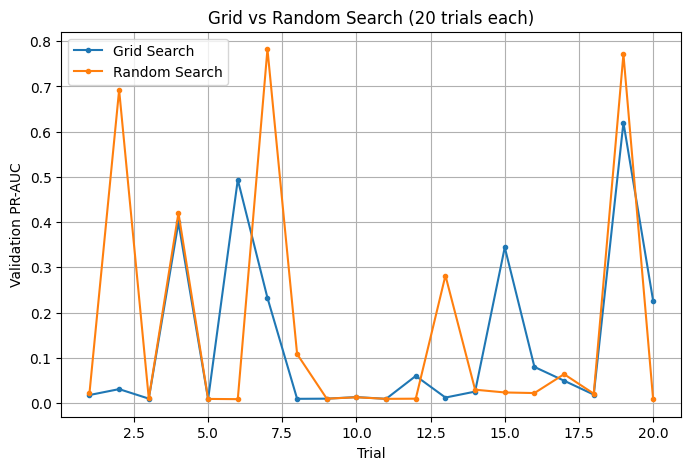

Why tune learning rate first? It controls update size and can determine whether training converges, diverges, or progresses too slowly.
Other diagnostics: overfitting (train accuracy high, validation low) → regularization/early stopping/more data; inability to fit one batch → check labels, loss, output activation, gradients and model capacity.


In [ ]:
# Q6B: Hyperparameter search – 20 grid candidates and 20 random candidates.
# Small subset and short training make the experiment practical in Colab.
Xsmall=Xtr[:1800]; ysmall=ytr[:1800]
Xval=Xte[:600]; yval=yte[:600]

learning_rates=[1e-4,5e-4,1e-3,5e-3]
hidden_sizes=[8,16,32]
dropouts=[0.0,0.2,0.4]
all_configs=list(itertools.product(learning_rates,hidden_sizes,dropouts))
grid_configs=all_configs[:20]
rng=np.random.default_rng(2026)
random_indices=rng.choice(len(all_configs),size=20,replace=False)
random_configs=[all_configs[i] for i in random_indices]

def evaluate_gru_config(config, seed=123):
    lr,hidden,dropout=config
    set_seed(seed)
    model=keras.Sequential([
        layers.Input((12,4)), layers.GRU(hidden,dropout=dropout),
        layers.Dense(1,activation="sigmoid")
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy")
    model.fit(Xsmall,ysmall,epochs=2,batch_size=128,verbose=0)
    probs=model.predict(Xval,verbose=0).ravel()
    score=average_precision_score(yval,probs)
    return score,model.count_params()

search_rows=[]
for method,configs in [("Grid Search",grid_configs),("Random Search",random_configs)]:
    for idx,cfg in enumerate(configs,1):
        score,params=evaluate_gru_config(cfg,seed=100+idx)
        search_rows.append({"method":method,"trial":idx,"learning_rate":cfg[0],
                            "hidden_size":cfg[1],"dropout":cfg[2],
                            "validation_PR_AUC":score,"parameters":params})
q6_search=pd.DataFrame(search_rows)
display(q6_search.sort_values("validation_PR_AUC",ascending=False).groupby("method").head(5))
best_q6=q6_search.loc[q6_search.groupby("method").validation_PR_AUC.idxmax()]
display(best_q6)
plt.figure(figsize=(8,5))
for method,grp in q6_search.groupby("method"):
    plt.plot(grp.trial,grp.validation_PR_AUC,marker=".",label=method)
plt.xlabel("Trial"); plt.ylabel("Validation PR-AUC"); plt.title("Grid vs Random Search (20 trials each)")
plt.legend(); plt.grid(True); plt.show()

print("Why tune learning rate first? It controls update size and can determine whether training converges, diverges, or progresses too slowly.")
print("Other diagnostics: overfitting (train accuracy high, validation low) → regularization/early stopping/more data; inability to fit one batch → check labels, loss, output activation, gradients and model capacity.")

# Q7 – Design a Long-Horizon Sequence Model from First Principles (10 marks)

The task is to forecast every five minutes using 2,016 historical steps (one week). The example model combines:
- A compact GRU encoder over the 2,016-step sequence.
- Explicit daily and weekly seasonal reference values as additional inputs.
- A dense output head.

This is one defensible design proposal; measured latency is hardware-dependent and must be checked against the 20 ms requirement on the target kiosk CPU.

Sequence input shape: (1584, 2016, 1) Seasonal input shape: (1584, 2)


Model: "functional_69"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ week_sequence       │ (None, 2016, 1)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ compact_GRU_encoder │ (None, 16)        │        912 │ week_sequence[0]… │
│ (GRU)               │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ daily_weekly_refer… │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 18)        │          0 │ compact_GRU_enco… │
│ (Concatenate)       │                   │            │ daily_weekly_ref… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_72 (Dense)    │ (None, 16)        │        304 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_73 (Dense)    │ (None, 1)         │         17 │ dense_72[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,233 (4.82 KB)

 Trainable params: 1,233 (4.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
68/68 ━━━━━━━━━━━━━━━━━━━━ 50s 694ms/step - loss: 341.3501 - mae: 17.4983 - val_loss: 81.6063 - val_mae: 8.0359
Epoch 2/5
68/68 ━━━━━━━━━━━━━━━━━━━━ 47s 695ms/step - loss: 76.6959 - mae: 7.8174 - val_loss: 9.0925 - val_mae: 2.3798
Epoch 3/5
68/68 ━━━━━━━━━━━━━━━━━━━━ 47s 690ms/step - loss: 10.9145 - mae: 2.7339 - val_loss: 4.8882 - val_mae: 1.8563
Epoch 4/5
68/68 ━━━━━━━━━━━━━━━━━━━━ 47s 695ms/step - loss: 2.9248 - mae: 1.4154 - val_loss: 4.1520 - val_mae: 1.7368
Epoch 5/5
68/68 ━━━━━━━━━━━━━━━━━━━━ 47s 697ms/step - loss: 1.5444 - mae: 1.0013 - val_loss: 1.7785 - val_mae: 1.1198
Test MAE: 0.9178910851478577
Test RMSE: 1.1302099389036995
Measured CPU/GPU runtime per forecast (ms): 115.30588327522157
Training time (seconds): 273.1630883216858
Peak-hour MAE: 0.7610538601875305
Peak-hour RMSE: 0.9783232722558449


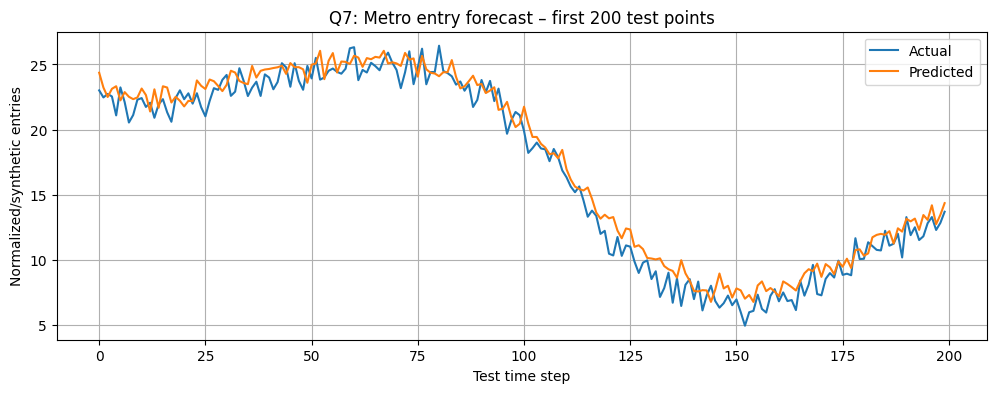

Trainable parameters: 1233
Longest recurrent gradient path through the GRU encoder can span up to 2016 time steps.
Daily/weekly reference inputs provide direct paths from t-288 and t-2016 to the forecast head.
Latency target: under 20 ms. Compare the measured value above with this threshold on the target CPU.


In [ ]:
# Q7: Build a synthetic 5-minute metro-entry time series.
# 288 points/day; one week = 2016 points.
POINTS_PER_DAY=288
WINDOW=7*POINTS_PER_DAY
def make_metro_series(n=3600,seed=77):
    rng=np.random.default_rng(seed)
    t=np.arange(n)
    tod=t%POINTS_PER_DAY
    daily=18+7*np.sin(2*np.pi*(tod-60)/POINTS_PER_DAY)+3*np.sin(4*np.pi*tod/POINTS_PER_DAY)
    weekly=2.5*np.sin(2*np.pi*t/(7*POINTS_PER_DAY))
    morning_peak=8*np.exp(-0.5*((tod-90)/18)**2)
    evening_peak=6*np.exp(-0.5*((tod-210)/22)**2)
    return (daily+weekly+morning_peak+evening_peak+rng.normal(0,0.8,n)).astype("float32")

metro=make_metro_series()
# Build sequences; additional seasonal features are the values at t-1 day and t-1 week.
Xseq=[]; Xseason=[]; ymetro=[]; target_times=[]
for target in range(WINDOW,len(metro)):
    Xseq.append(metro[target-WINDOW:target])
    Xseason.append([metro[target-POINTS_PER_DAY],metro[target-WINDOW]])
    ymetro.append(metro[target])
    target_times.append(target)
Xseq=np.array(Xseq,dtype="float32")[...,None]
Xseason=np.array(Xseason,dtype="float32")
ymetro=np.array(ymetro,dtype="float32")
print("Sequence input shape:",Xseq.shape,"Seasonal input shape:",Xseason.shape)

# Chronological train/test split
split=int(0.8*len(ymetro))
Xs_tr,Xs_te=Xseq[:split],Xseq[split:]
Xf_tr,Xf_te=Xseason[:split],Xseason[split:]
ym_tr,ym_te=ymetro[:split],ymetro[split:]

seq_in=keras.Input(shape=(WINDOW,1),name="week_sequence")
season_in=keras.Input(shape=(2,),name="daily_weekly_reference")
encoded=layers.GRU(16, name="compact_GRU_encoder")(seq_in)
combined=layers.Concatenate()([encoded,season_in])
hidden=layers.Dense(16,activation="relu")(combined)
forecast=layers.Dense(1)(hidden)
metro_model=keras.Model([seq_in,season_in],forecast)
metro_model.compile(optimizer="adam",loss="mse",metrics=["mae"])
metro_model.summary()
start=time.time()
metro_model.fit([Xs_tr,Xf_tr],ym_tr,validation_split=0.15,epochs=5,batch_size=16,verbose=1)
q7_training_seconds=time.time()-start

# Forecast error and latency
start=time.time()
metro_pred=metro_model.predict([Xs_te,Xf_te],batch_size=1,verbose=0).ravel()
latency_ms=1000*(time.time()-start)/len(Xs_te)
mae=mean_absolute_error(ym_te,metro_pred)
rmse=np.sqrt(mean_squared_error(ym_te,metro_pred))
print("Test MAE:",mae)
print("Test RMSE:",rmse)
print("Measured CPU/GPU runtime per forecast (ms):",latency_ms)
print("Training time (seconds):",q7_training_seconds)

# Peak-hour error: local time-of-day index 80–110 or 195–225
test_targets=np.array(target_times[split:])
tod=test_targets%POINTS_PER_DAY
peak_mask=((tod>=80)&(tod<=110))|((tod>=195)&(tod<=225))
if peak_mask.any():
    print("Peak-hour MAE:",mean_absolute_error(ym_te[peak_mask],metro_pred[peak_mask]))
    print("Peak-hour RMSE:",np.sqrt(mean_squared_error(ym_te[peak_mask],metro_pred[peak_mask])))
else:
    print("No peak-hour samples in this small test segment; increase series length.")

plt.figure(figsize=(12,4))
plt.plot(ym_te[:200],label="Actual")
plt.plot(metro_pred[:200],label="Predicted")
plt.title("Q7: Metro entry forecast – first 200 test points")
plt.xlabel("Test time step"); plt.ylabel("Normalized/synthetic entries")
plt.legend(); plt.grid(True); plt.show()

# Q7 parameter count and rough gradient-path explanation
print("Trainable parameters:",metro_model.count_params())
print("Longest recurrent gradient path through the GRU encoder can span up to",WINDOW,"time steps.")
print("Daily/weekly reference inputs provide direct paths from t-288 and t-2016 to the forecast head.")
print("Latency target: under 20 ms. Compare the measured value above with this threshold on the target CPU.")

# Final consolidated results tables



In [ ]:
result_tables = {
    "Q1_forward_pass.csv": q1_forward,
    "Q1_parameter_counts.csv": q1_counts,
    "Q1_experiments.csv": q1_experiment,
    "Q2_gradient_results.csv": q2_df,
    "Q3_model_comparison.csv": q3_df,
    "Q4_IMDB_results.csv": q4_df,
    "Q5_path_lengths.csv": q5_paths,
    "Q5_gradient_results.csv": q5_grad_df,
    "Q6_hyperparameter_search.csv": q6_search,
}
for filename, table in result_tables.items():
    table.to_csv(filename,index=False)
    print("Saved:",filename)
print("\nQ7 summary:")
print({"MAE":float(mae),"RMSE":float(rmse),"latency_ms_per_forecast":float(latency_ms),
       "parameters":int(metro_model.count_params())})

Saved: Q1_forward_pass.csv
Saved: Q1_parameter_counts.csv
Saved: Q1_experiments.csv
Saved: Q2_gradient_results.csv
Saved: Q3_model_comparison.csv
Saved: Q4_IMDB_results.csv
Saved: Q5_path_lengths.csv
Saved: Q5_gradient_results.csv
Saved: Q6_hyperparameter_search.csv

Q7 summary:
{'MAE': 0.9178910851478577, 'RMSE': 1.1302099389036995, 'latency_ms_per_forecast': 115.30588327522157, 'parameters': 1233}


In [ ]:
import os
import glob
import zipfile
from google.colab import files

zip_name = "/content/Deep_Learning_Assignment_3_Results.zip"

# Find the notebook in the current Colab environment
notebooks = glob.glob("/content/*.ipynb")

with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as z:

    # Add notebook
    for notebook in notebooks:
        z.write(notebook, os.path.basename(notebook))
        print("Notebook added:", os.path.basename(notebook))

    # Add CSV result files
    csv_files = glob.glob("/content/*.csv")

    for file in csv_files:
        z.write(file, os.path.basename(file))
        print("Added:", os.path.basename(file))

print("\nZIP created successfully!")

# Download directly to your PC
files.download(zip_name)

Added: Q1_parameter_counts.csv
Added: Q4_IMDB_results.csv
Added: Q2_gradient_results.csv
Added: Q5_path_lengths.csv
Added: Q1_forward_pass.csv
Added: Q1_experiments.csv
Added: Q6_hyperparameter_search.csv
Added: Q3_model_comparison.csv
Added: Q5_gradient_results.csv

ZIP created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>